In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

def cm_to_inches(cm_tuple):
    return tuple(x / 2.54 for x in cm_tuple)

def setup_plotting_environment():
    plt.rcParams.update({'font.size': 6, 'font.family': 'Helvetica'})

setup_plotting_environment()

plot_folder = 'plots/DEG_analysis'
os.makedirs(plot_folder, exist_ok=True)

In [8]:
import sys
sys.path.append('..')
from constants import CELL_TYPE_COLORS, ALL_CELL_TYPES
ALL_CELL_TYPES_EXCLUDE = [cell for cell in ALL_CELL_TYPES if cell not in ["ILC", "pDC"]]

# info on cytokines
cytokine_info = pd.read_excel("../../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="all_cytokines")
cytokine_info["single_gene"] = cytokine_info["gene"].str.split(",").str[0]

cytokine_info_parse = cytokine_info[cytokine_info["parse_cytokine"]]
cytokine_info_order = pd.read_excel("../../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="suggested_order")

CYTOKINE_ORDER = list(cytokine_info_order["name"])

In [9]:
wells = ["H7", "H8", "H9", "H10", "H11", "H12"]

relevant_cell_type_conversion = {
    "Treg": "Treg",
    "CD14_Mono": "CD14 Mono",
    "HSPC": "HSPC", 
    "pDC": "pDC",
    "NKT": "NKT",
    "other": "granulocyte",
    "CD16_Mono": "CD16 Mono",
    "CD56-bright_NK": "NK CD56hi",
    "CD56-dim_NK": "NK CD56low",
    "MAIT": "MAIT",
    "cDC": "cDC",
    "ILC": "ILC",
    "CD8": "CD8 T cell",
    "B": "B cell",
    "CD4": "CD4 T cell",
    "HPSC": "HPSC"
}

#### Load original DEGs

In [ ]:
def create_edger_val_df(result_df, val_type):
    """
    Creates a DataFrame from EdgeR results with a MultiIndex of (cell_type, cytokine) columns.
    
    Parameters:
    -----------
    result_df : pandas.DataFrame
        The EdgeR results DataFrame containing gene, cell_type, cytokine, and value columns.
    val_type : str
        The column name in result_df to use as values (e.g., 'adj_p_value', 'log_fc', 'logCPM').
        
    Returns:
    --------
    pandas.DataFrame
        A pivoted DataFrame with genes as index and MultiIndex columns of (cell_type, cytokine),
        containing the specified values. Missing combinations are filled with NaN.
    """
    # rename 
    df = result_df[[val_type, "gene", "cell_type", "cytokine"]]
    # reformat to columns = (cell_type, cytokine)
    df = df.pivot(index="gene",columns=["cell_type", "cytokine"], values=val_type)
    # create tuples of (cell_type, cytokine) for all combinations
    column_tuples = [(cell_type, cytokine) 
                    for cell_type in ALL_CELL_TYPES 
                    for cytokine in CYTOKINE_ORDER]
    df = df.reindex(pd.MultiIndex.from_tuples(column_tuples), axis=1)
    return df


# basically a concatenated table of all DEGs
edger_results = pd.read_csv(os.path.join("../../data/", "EdgeR_DEGs_all.csv"), index_col=0)
edger_results = edger_results.rename(columns={"celltype": "cell_type"})

edger_results = edger_results[edger_results["cell_type"].isin(relevant_cell_type_conversion.keys())]
edger_results["cell_type"] = edger_results["cell_type"].map(relevant_cell_type_conversion)

edger_df_padj = create_edger_val_df(edger_results, "adj_p_value")
edger_df_log2CPM = create_edger_val_df(edger_results, "logCPM")
edger_df_log2FoldChange = create_edger_val_df(edger_results, "log_fc")

#### Load per-well DEGs

In [3]:
input_data_folder = "../../data/DEG_vs_separate_PBS"
files = os.listdir(input_data_folder)

In [ ]:
def create_edger_val_df_with_wells(result_df, val_type):
    """
    Creates a DataFrame from EdgeR results with a MultiIndex of (cell_type, cytokine) columns.
    
    Parameters:
    -----------
    result_df : pandas.DataFrame
        The EdgeR results DataFrame containing gene, cell_type, cytokine, and value columns.
    val_type : str
        The column name in result_df to use as values (e.g., 'adj_p_value', 'log_fc', 'logCPM').
        
    Returns:
    --------
    pandas.DataFrame
        A pivoted DataFrame with genes as index and MultiIndex columns of (cell_type, cytokine),
        containing the specified values. Missing combinations are filled with NaN.
    """
    # rename 
    df = result_df[[val_type, "gene", "cell_type", "cytokine", "pbs_well"]]
    # reformat to columns = (cell_type, cytokine, well)
    df = df.pivot(index="gene",columns=["cell_type", "cytokine", "pbs_well"], values=val_type)
    # create tuples of (cell_type, cytokine, well) for all combinations
    column_tuples = [(cell_type, cytokine, well) 
                    for cell_type in ALL_CELL_TYPES 
                    for cytokine in CYTOKINE_ORDER
                    for well in wells]
    df = df.reindex(pd.MultiIndex.from_tuples(column_tuples), axis=1)
    return df

dfs = []
for file in files:
    df = pd.read_csv(os.path.join(input_data_folder, file), index_col=0)
    dfs.append(df)
df = pd.concat(dfs)

df = df.rename(columns={"celltype": "cell_type", "variable": "gene"})
df['cell_type'] = df['cell_type'].map(relevant_cell_type_conversion)
edger_df_log2fc_wells = create_edger_val_df_with_wells(df, "log_fc")
edger_df_padj_wells = create_edger_val_df_with_wells(df, "adj_p_value")

NameError: name 'relevant_cell_type_conversion' is not defined

In [15]:
edger_df_log2fc_wells["CD14 Mono"]["IL-32-beta"].corr()

,H7,H8,H9,H10,H11,H12
H7,1.000000,0.987088,0.988839,0.988721,0.980954,0.980241
H8,0.987088,1.000000,0.991413,0.987025,0.979003,0.972062
H9,0.988839,0.991413,1.000000,0.991620,0.987936,0.982675
H10,0.988721,0.987025,0.991620,1.000000,0.987913,0.986732
H11,0.980954,0.979003,0.987936,0.987913,1.000000,0.989242
H12,0.980241,0.972062,0.982675,0.986732,0.989242,1.000000


In [7]:
corrs = []
for cytokine in CYTOKINE_ORDER:
    for cell_type in ALL_CELL_TYPES:
        subset = edger_df_log2fc_wells.loc[:, (cell_type, cytokine, slice(None))]
        corr = subset.corr()
        np.fill_diagonal(corr.values, np.nan)
        mean_corr = corr.mean().mean()
        row = {
            "cell_type": cell_type,
            "cytokine": cytokine,
            "mean_corr": mean_corr
        }
        corrs.append(row)
corrs = pd.DataFrame(corrs)        

In [8]:
response_magnitudes = pd.read_csv("output_tables/2_response_magnitudes.csv", index_col=0).unstack()
response_magnitudes = response_magnitudes.reset_index()
response_magnitudes.columns = ["cell_type", "cytokine", "response_magnitude"]
magnitude_threshold = pd.read_csv("output_tables/2_response_magnitude_thresholds.csv", index_col=0)
magnitude_threshold.columns = ['threshold']

In [9]:
merged_df = pd.merge(corrs, response_magnitudes, on=['cell_type', 'cytokine'])
merged_df = merged_df.dropna()

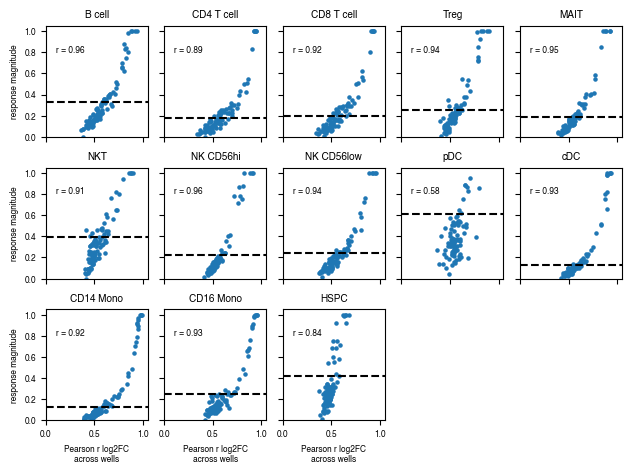

In [10]:
n_cell_types = len(merged_df["cell_type"].unique())
n_cols = 5
n_rows = (n_cell_types + n_cols - 1) // n_cols  # Ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=cm_to_inches((16, 4*n_rows)))
axes = axes.flatten()

for idx, cell_type in enumerate(merged_df["cell_type"].unique()):
    subset = merged_df[merged_df["cell_type"] == cell_type]
    axes[idx].scatter(subset["mean_corr"], subset["response_magnitude"], s=5)
    r = np.corrcoef(subset["mean_corr"], subset["response_magnitude"])[0,1]
    axes[idx].axhline(y=magnitude_threshold.loc[cell_type, "threshold"], color='black', linestyle='--', alpha=1)
    axes[idx].set_xlabel("Pearson r log2FC\nacross wells")
    axes[idx].set_ylabel("response magnitude")
    axes[idx].set_title(f"{cell_type}")
    axes[idx].set_xlim(0,1.05)
    axes[idx].set_ylim(0,1.05)
    axes[idx].text(0.1, 0.8, f"r = {r:.2f}")
    axes[idx].label_outer()
    
# Hide any unused subplots
for idx in range(len(merged_df["cell_type"].unique()), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"corr_vs_magnitude.{format}"), dpi=300)

## Find consistent outlier genes

In [11]:
edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean().unstack()
edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std().unstack()
fc_mean_std = pd.concat([edger_df_fc_mean, edger_df_fc_std], axis=1)
fc_mean_std.reset_index(inplace=True)
fc_mean_std.columns = ["cell_type", "cytokine", "gene", "fc_mean", "fc_std"]
fc_mean_std = fc_mean_std.dropna().copy()

C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\2533910737.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean().unstack()
C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\2533910737.py:2: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std().unstack()


In [12]:
constant_add = 0.25
fc_mean_std['ratio'] = fc_mean_std['fc_std']/(abs(fc_mean_std['fc_mean'])+constant_add)
fc_mean_std['high_ratio'] = fc_mean_std['ratio'] > 1

In [13]:
fc_mean_std = fc_mean_std[fc_mean_std['cell_type'].isin(ALL_CELL_TYPES_EXCLUDE)]
high_counts_gene = (fc_mean_std[fc_mean_std['high_ratio']]
                   .groupby(['cell_type', 'gene'])
                   .size()
                   .reindex(pd.MultiIndex.from_product([fc_mean_std['cell_type'].unique(), 
                                                      fc_mean_std['gene'].unique()], 
                                                     names=['cell_type', 'gene']), 
                           fill_value=0)
                   .sort_values(ascending=False))
high_counts_gene = high_counts_gene.reset_index()
high_counts_gene.columns = ["cell_type", "gene", "count"]

<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\2437713021.py:12: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel(f"$\sigma$(log2FC)")


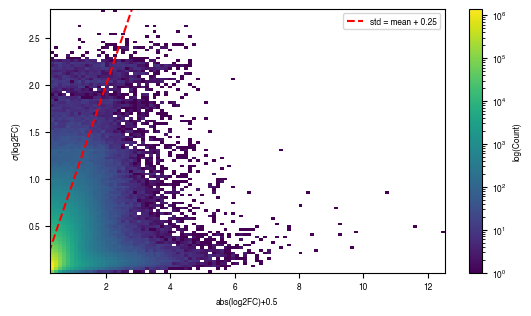

In [14]:
plt.figure(figsize=cm_to_inches((14, 8)))
plt.hist2d((abs(fc_mean_std['fc_mean'])+constant_add).values.flatten(), 
           fc_mean_std['fc_std'].values.flatten(),
           bins=100, 
           cmap='viridis',
           rasterized=True,
           norm=matplotlib.colors.LogNorm())
plt.plot([0, 10], [0, 10], color="red", linestyle="--", label=f"std = mean + {constant_add}")
plt.colorbar(label='log(Count)')
plt.legend(loc="upper right")
plt.xlabel("abs(log2FC)+0.5")
plt.ylabel(f"$\sigma$(log2FC)")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"fc_mean_std_2dhist.png"), dpi=300)

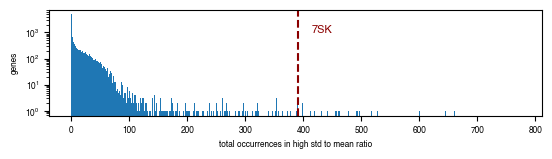

In [15]:
high_counts_gene_across = high_counts_gene.groupby('gene')["count"].sum()
plt.figure(figsize=cm_to_inches((14, 4)))
# Changed bin step from 2 to 1 to ensure a separate bar for 0-valued counts
plt.hist(high_counts_gene_across, bins=np.arange(-0.5, max(high_counts_gene_across)+1.5, 1))
plt.axvline(x=high_counts_gene_across['7SK'], color='darkred', linestyle='--', label='7SK')
plt.yscale('log')
plt.text(high_counts_gene_across['7SK']+25, 1000, '7SK', fontsize=8, color='darkred')
plt.xlabel("total occurrences in high std to mean ratio")
plt.ylabel("genes")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"high_counts_gene_across.png"), dpi=300)

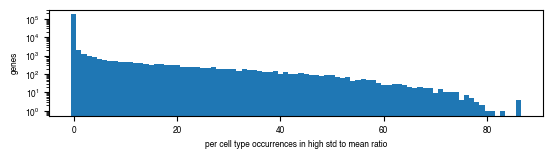

In [16]:
plt.figure(figsize=cm_to_inches((14, 4)))
# Changed bin step from 2 to 1 to ensure a separate bar for 0-valued counts
plt.hist(high_counts_gene['count'], bins=np.arange(-0.5, max(high_counts_gene['count'])+1.5, 1))
plt.yscale('log')
plt.xlabel("per cell type occurrences in high std to mean ratio")
plt.ylabel("genes")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"high_counts_gene_per_cell.png"), dpi=300)

In [17]:
high_counts_gene["high"] = high_counts_gene['count'] > 10
high_cross_cell_types = high_counts_gene[high_counts_gene['high']]['gene'].value_counts().reindex(high_counts_gene['gene'].unique(), fill_value=0)

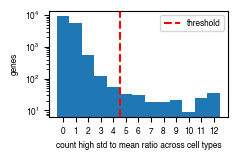

In [18]:
plt.figure(figsize=cm_to_inches((6, 4)))
# Create bins for each possible value
bins = np.arange(-0.5, high_cross_cell_types.max() + 1.5, 1)
plt.hist(high_cross_cell_types, bins=bins)
plt.xticks(range(high_cross_cell_types.max() + 1))
plt.axvline(x=4.5, color='red', linestyle='--', label='threshold')
plt.legend(loc='upper right')
plt.yscale('log')
plt.xlabel("count high std to mean ratio across cell types")
plt.ylabel("genes")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"high_counts_gene_across_cell_types.png"), dpi=300)

In [19]:
questionable_genes = pd.Series(high_cross_cell_types[high_cross_cell_types > 4].index)
questionable_genes.to_csv('output_tables/questionable_genes.csv', index=False)

## Check impact on lfc plots

In [20]:
edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean()
edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std()

C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\608093947.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  edger_df_fc_mean = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).mean()
C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\608093947.py:2: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  edger_df_fc_std = edger_df_log2fc_wells.groupby(level=[0,1], axis=1).std()


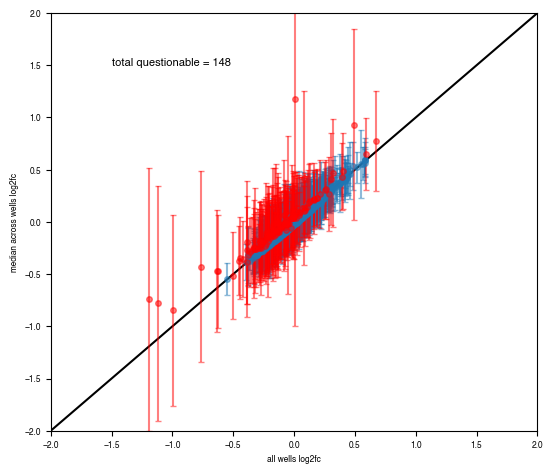

In [21]:
cytokine = "4-1BBL"
cell_type = "B cell"
x = edger_df_log2FoldChange.loc[:, (cell_type, cytokine)]
y = edger_df_fc_mean.loc[:, (cell_type, cytokine)]

x_genes = x.dropna().index
y_genes = y.dropna().index

genes = x_genes.intersection(y_genes)
x = x.loc[genes]
y = y.loc[genes]
y_error = edger_df_fc_std.loc[genes, (cell_type, cytokine)]
questionable_filter = [g for g in questionable_genes.values if g in genes]
other_filter = [g for g in genes if g not in questionable_filter]

plt.figure(figsize=cm_to_inches((14, 12)))
plt.xlabel("all wells log2fc")
plt.ylabel("median across wells log2fc")
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.text(-1.5, 1.5, f"total questionable = {len(questionable_filter)}", fontsize=8)
plt.plot([-4, 4], [-4, 4], color="black")
plt.errorbar(x[other_filter], y[other_filter], yerr=y_error[other_filter], fmt='o', markersize=4, capsize=2, alpha=0.5, rasterized=True)
plt.errorbar(x[questionable_filter], y[questionable_filter], yerr=y_error[questionable_filter], fmt='o', markersize=4, capsize=2, alpha=0.5, color="red", rasterized=True)
plt.tight_layout()
for format in ["png", "svg"]:
    plt.savefig(os.path.join(plot_folder, f"log2fc_vs_median_log2fc.{format}"), dpi=300)

# consistency filtering

In [22]:
edger_df_padj = edger_df_padj[~edger_df_padj.index.isin(questionable_genes.values)]
edger_df_padj_wells = edger_df_padj_wells[~edger_df_padj_wells.index.isin(questionable_genes.values)]
edger_df_log2fc_wells = edger_df_log2fc_wells[~edger_df_log2fc_wells.index.isin(questionable_genes.values)]

In [23]:
edger_df_padj_significant = edger_df_padj.fillna(1) < 0.05

In [24]:
edger_df_padj_wells_significant = edger_df_padj_wells.fillna(1) < 0.1
edger_df_log2fc_present = abs(edger_df_log2fc_wells.fillna(0)) > 0.25
criterion = edger_df_log2fc_present * edger_df_padj_wells_significant

C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\2476621888.py:3: UserWarning: evaluating in Python space because the '*' operator is not supported by numexpr for the bool dtype, use '&' instead.
  criterion = edger_df_log2fc_present * edger_df_padj_wells_significant


In [25]:
filtered_degs_well = (criterion.groupby(level=[0,1], axis=1).sum() > 3) * edger_df_padj_significant

C:\Users\loesi\AppData\Local\Temp\ipykernel_8608\1521920973.py:1: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  filtered_degs_well = (criterion.groupby(level=[0,1], axis=1).sum() > 3) * edger_df_padj_significant


In [26]:
no_significant_well = filtered_degs_well.sum(axis=0)
no_significant_all = edger_df_padj_significant.sum(axis=0)

In [27]:
no_significant = pd.concat([no_significant_all, no_significant_well], axis=1)
no_significant.columns = ["all", "well"]

no_significant["ratio"] = (no_significant["well"]+1)/(no_significant["all"]+1)

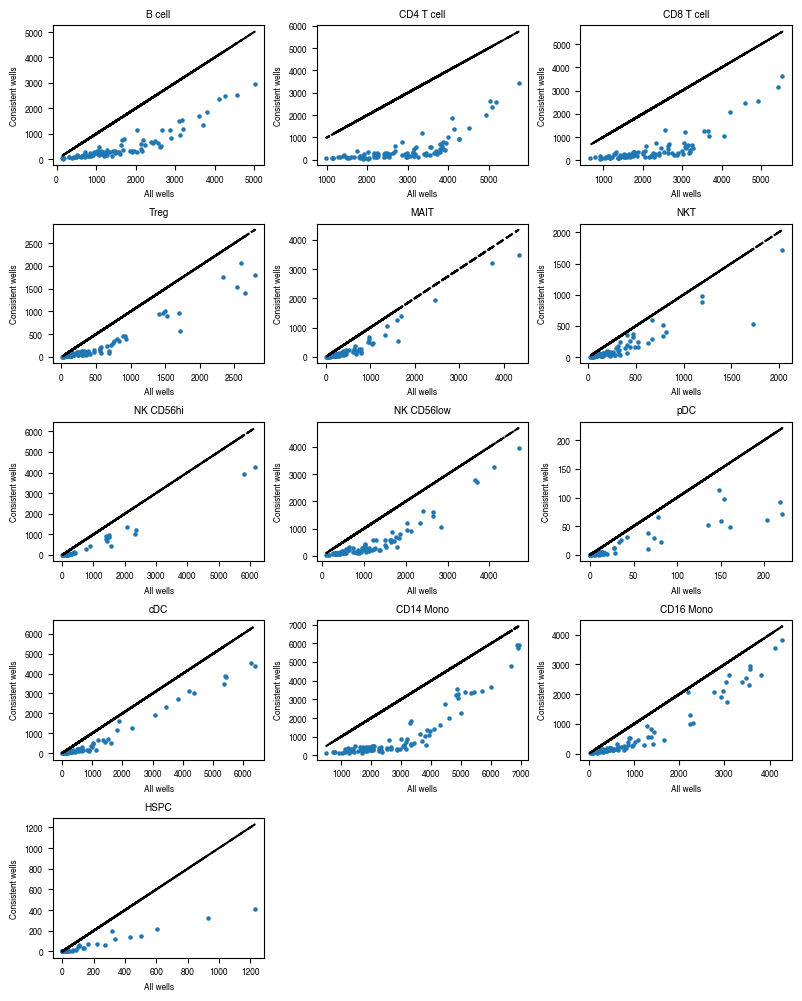

In [28]:
cell_types = no_significant.index.get_level_values(0).unique()
n_cols = 3
n_rows = (len(cell_types) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(8, 2*n_rows))
axes = axes.flatten()

for idx, cell_type in enumerate(cell_types):
    cell_data = no_significant.loc[cell_type]
    axes[idx].scatter(cell_data["all"], cell_data["well"], s=5)
    axes[idx].plot(cell_data["all"], cell_data["all"], color="black", linestyle="--")
    axes[idx].set_title(f"{cell_type}")
    axes[idx].set_xlabel("All wells")
    axes[idx].set_ylabel("Consistent wells")

# Hide empty subplots
for idx in range(len(cell_types), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

In [29]:
edger_df_padj[~(criterion.T.groupby(level=[0,1]).sum().T > 3)] = 1

In [30]:
edger_df_padj.to_csv("output_tables/external_filtered_padj_by_consistency.csv")

In [34]:
(edger_df_padj < 0.05).sum()

B cell  IL-1-alpha     753
        IL-1-beta     1533
        IL-1Ra         282
        IL-18           87
        IL-33           77
                      ... 
HSPC    Noggin           3
        Decorin          0
        IL-8             0
        IL-16            2
        IL-32-beta     324
Length: 1170, dtype: int64